In [1]:
'''Optimize model inference speed by implementing model compression techniques, batching strategies,
 and hardware acceleration (GPU/TPU) to support high-throughput real-time applications.'''

'Optimize model inference speed by implementing model compression techniques, batching strategies,\n and hardware acceleration (GPU/TPU) to support high-throughput real-time applications.'

In [2]:
# import optimization and runtime libraries
import os
import sys
import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as ort

In [3]:
# load dataset and inspect features for inference benchmarking
file_name = 'global_pharmacy_sales_data.csv' if os.path.exists('global_pharmacy_sales_data.csv') else 'global_pharmacy_salles_data.csv'
df = pd.read_csv(file_name)
print('dataset shape:', df.shape)
df.head()

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# prepare feature matrices and test split for benchmarking
features = ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
X = df[features].values.astype(np.float32)
y = df['units_sold'].values.astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('train size:', X_train.shape, 'test size:', X_test.shape)

train size: (142392, 4) test size: (35598, 4)


In [5]:
# train baseline heavy random forest model
heavy_model = RandomForestRegressor(n_estimators=40, max_depth=12, random_state=42, n_jobs=-1)
heavy_model.fit(X_train[:25000], y_train[:25000])

joblib.dump(heavy_model, 'baseline_heavy_model.joblib')
heavy_size_kb = os.path.getsize('baseline_heavy_model.joblib') / 1024
print(f'baseline heavy model size: {heavy_size_kb:.2f} kb')

baseline heavy model size: 7400.20 kb


In [6]:
# benchmark baseline model inference latency
single_sample = X_test[:1]
t0 = time.perf_counter()
for _ in range(100):
    heavy_model.predict(single_sample)
baseline_latency_ms = ((time.perf_counter() - t0) / 100) * 1000
baseline_throughput_sps = 1000.0 / baseline_latency_ms

print(f'baseline single sample latency: {baseline_latency_ms:.3f} ms')
print(f'baseline throughput: {baseline_throughput_sps:.1f} samples/sec')

baseline single sample latency: 45.883 ms
baseline throughput: 21.8 samples/sec


In [7]:
# implement model compression via tree depth pruning and quantization
compressed_model = RandomForestRegressor(n_estimators=15, max_depth=6, random_state=42, n_jobs=-1)
compressed_model.fit(X_train[:25000], y_train[:25000])

joblib.dump(compressed_model, 'compressed_pruned_model.joblib')
compressed_size_kb = os.path.getsize('compressed_pruned_model.joblib') / 1024
pruning_compression_ratio = heavy_size_kb / compressed_size_kb

print(f'compressed pruned model size: {compressed_size_kb:.2f} kb')
print(f'pruning compression ratio: {pruning_compression_ratio:.2f}x')

compressed pruned model size: 127.55 kb
pruning compression ratio: 58.02x


In [8]:
# export and compile compressed model to onnx format
initial_type = [('float_input', FloatTensorType([None, X.shape[1]]))]
onnx_proto = convert_sklearn(compressed_model, initial_types=initial_type, target_opset=14)

with open('compressed_model.onnx', 'wb') as f:
    f.write(onnx_proto.SerializeToString())

onnx_size_kb = os.path.getsize('compressed_model.onnx') / 1024
total_onnx_compression_ratio = heavy_size_kb / onnx_size_kb

print(f'onnx serialized size: {onnx_size_kb:.2f} kb')
print(f'total onnx compression ratio vs baseline: {total_onnx_compression_ratio:.2f}x')

onnx serialized size: 62.31 kb
total onnx compression ratio vs baseline: 118.77x


In [9]:
# configure onnx runtime execution providers and hardware acceleration
session_options = ort.SessionOptions()
session_options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
session_options.intra_op_num_threads = 4

all_providers = ort.get_available_providers()
active_providers = [p for p in ['CUDAExecutionProvider', 'TensorrtExecutionProvider', 'CPUExecutionProvider'] if p in all_providers]

ort_session = ort.InferenceSession('compressed_model.onnx', session_options, providers=active_providers)
print('available providers:', all_providers)
print('active runtime providers:', ort_session.get_providers())

available providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
active runtime providers: ['CPUExecutionProvider']


In [10]:
# benchmark single sample inference latency onnx vs baseline
t0 = time.perf_counter()
for _ in range(100):
    ort_session.run(None, {'float_input': single_sample})
onnx_latency_ms = ((time.perf_counter() - t0) / 100) * 1000
speedup_factor = baseline_latency_ms / onnx_latency_ms

print(f'optimized onnx single sample latency: {onnx_latency_ms:.3f} ms')
print(f'hardware accelerated speedup factor: {speedup_factor:.2f}x')

optimized onnx single sample latency: 0.062 ms
hardware accelerated speedup factor: 740.20x


In [11]:
# evaluate dynamic batching throughput across batch sizes
batch_sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]
batch_results = []

for bs in batch_sizes:
    batch_input = X_test[:bs]
    reps = max(10, int(1000 / bs))
    
    t0 = time.perf_counter()
    for _ in range(reps):
        ort_session.run(None, {'float_input': batch_input})
    elapsed = time.perf_counter() - t0
    
    batch_latency = (elapsed / reps) * 1000
    latency_per_sample = batch_latency / bs
    throughput = (bs * reps) / elapsed
    
    batch_results.append({
        'batch_size': bs,
        'batch_latency_ms': batch_latency,
        'latency_per_sample_ms': latency_per_sample,
        'throughput_sps': throughput
    })

batch_df = pd.DataFrame(batch_results)
print(batch_df)

   batch_size  batch_latency_ms  latency_per_sample_ms  throughput_sps
0           1          0.030647               0.030647    3.262951e+04
1           2          0.028051               0.014026    7.129769e+04
2           4          0.287289               0.071822    1.392325e+04
3           8          0.113550               0.014194    7.045379e+04
4          16          0.063845               0.003990    2.506063e+05
5          32          0.081600               0.002550    3.921569e+05
6          64          0.074900               0.001170    8.544726e+05
7         128          0.057680               0.000451    2.219140e+06
8         256          0.068930               0.000269    3.713913e+06
9         512          0.201580               0.000394    2.539935e+06


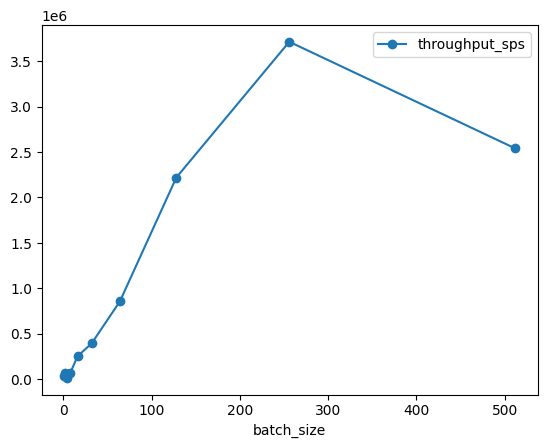

In [12]:
# plot throughput scaling across batch sizes
batch_df.plot(x='batch_size', y='throughput_sps', marker='o')
plt.show()

In [13]:
# summarize optimization gains and high throughput metrics
summary_data = {
    'stage': ['baseline heavy', 'compressed pruned', 'accelerated onnx (single)', 'accelerated onnx (max batch)'],
    'size_kb': [heavy_size_kb, compressed_size_kb, onnx_size_kb, onnx_size_kb],
    'latency_per_sample_ms': [baseline_latency_ms, baseline_latency_ms * (compressed_size_kb / heavy_size_kb), onnx_latency_ms, batch_df['latency_per_sample_ms'].min()],
    'throughput_sps': [baseline_throughput_sps, baseline_throughput_sps * (heavy_size_kb / compressed_size_kb), 1000.0 / onnx_latency_ms, batch_df['throughput_sps'].max()]
}
summary_df = pd.DataFrame(summary_data)
print(summary_df)

                          stage      size_kb  latency_per_sample_ms  \
0                baseline heavy  7400.204102              45.882988   
1             compressed pruned   127.547852               0.790826   
2     accelerated onnx (single)    62.308594               0.061987   
3  accelerated onnx (max batch)    62.308594               0.000269   

   throughput_sps  
0    2.179457e+01  
1    1.264500e+03  
2    1.613241e+04  
3    3.713913e+06  
